<a href="https://colab.research.google.com/github/JulioRan09/Porgramacion-Predictiva/blob/main/276572_Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

In [1]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error

import statsmodels.api as sm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [2]:
df = pd.read_csv('/content/college.csv')
df.head()

,id,name,salary,cost,public,location
0,1,Massachusetts Institute of Technology (MIT),119000,189300,Private,NE
1,2,Harvard University,121000,189600,Private,NE
2,3,Dartmouth College,123000,188400,Private,NE
3,4,Princeton University,123000,188700,Private,NE
4,5,Yale University,110000,194200,Private,NE


In [3]:
#Transformar location a columna categórica
df['location'].astype('category')

,location
0,NE
1,NE
2,NE
3,NE
4,NE
...,...
80,W
81,W
82,W
83,W


In [4]:
df[['salary', 'cost']].describe()


,salary,cost
count,85.000000,85.000000
mean,95898.823529,142434.470588
std,11937.121912,53913.064578
min,74900.000000,18260.000000
25%,87100.000000,84670.000000
50%,93200.000000,169200.000000
75%,105000.000000,188700.000000
max,123000.000000,227300.000000


In [5]:
#Contamos los datos por categoria de location
cuenta = df[['location']].value_counts()
cuenta

,count
location,
NE,25
W,21
S,20
MW,19


In [6]:
pub = df['public'].value_counts()
pub

,count
public,
Private,50
Public,35


In [7]:
#Convertimos la variable location utilizando hot encoding
encoder = OneHotEncoder(sparse_output= False, drop='first')
encoded_data = encoder.fit_transform(df[['location']])
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(['location']))

print(encoded_df)

    location_NE  location_S  location_W
0           1.0         0.0         0.0
1           1.0         0.0         0.0
2           1.0         0.0         0.0
3           1.0         0.0         0.0
4           1.0         0.0         0.0
..          ...         ...         ...
80          0.0         0.0         1.0
81          0.0         0.0         1.0
82          0.0         0.0         1.0
83          0.0         0.0         1.0
84          0.0         0.0         1.0

[85 rows x 3 columns]


In [8]:
#Concatenar el encoded y el df original
df_encoded = pd.concat([df, encoded_df], axis=1)
df_encoded.head()

,id,name,salary,cost,public,location,location_NE,location_S,location_W
0,1,Massachusetts Institute of Technology (MIT),119000,189300,Private,NE,1.0,0.0,0.0
1,2,Harvard University,121000,189600,Private,NE,1.0,0.0,0.0
2,3,Dartmouth College,123000,188400,Private,NE,1.0,0.0,0.0
3,4,Princeton University,123000,188700,Private,NE,1.0,0.0,0.0
4,5,Yale University,110000,194200,Private,NE,1.0,0.0,0.0


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




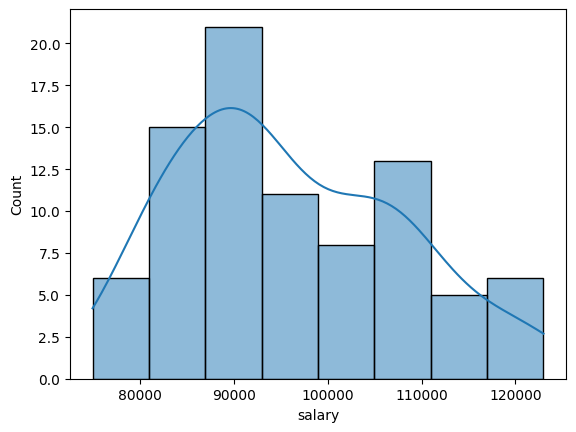

In [9]:
#Histograma
sns.histplot(df['salary'], kde=True)
plt.show()

## Interpretación
La distribución de los salarios presenta una mayor concentración de observaciones alrededor de los 90,000 dólares, que corresponde aproximadamente a la moda de la distribución. Además, se observan valores distribuidos entre 75,000 y 125,000 dólares, con una ligera acumulación en la zona de salarios más bajos. Visualmente, la distribución no parece perfectamente simétrica, por lo que podría diferir de una distribución normal.

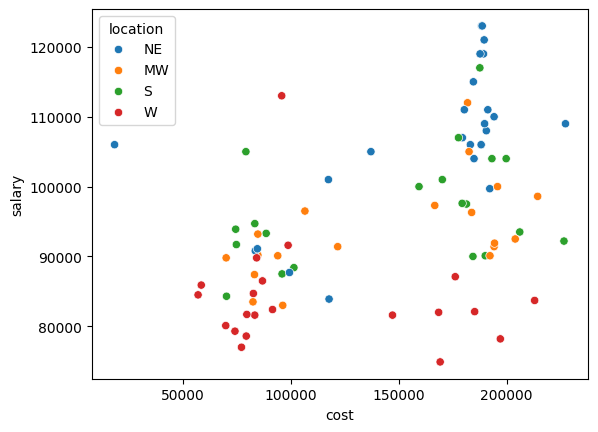

In [10]:
#Diagrama de dispersión
sns.scatterplot(data=df, x='cost', y='salary', hue='location')
plt.show()

## Interpretación
Se realizó un diagrama de dispersión por región para analizar la relación entre el costo de la universidad y el salario de los egresados. Para la región `NE`, se observa una tendencia positiva relativamente clara: a medida que aumenta el costo, también tiende a aumentar el salario.

En las regiones `MW` y `S` también existe una relación positiva, aunque menos marcada. Por otro lado, en la región `W` la relación parece ser más débil, ya que se observan salarios similares para distintos niveles de costo.

En general, el costo parece estar asociado positivamente con el salario, pero la intensidad de esta relación varía entre regiones.

/tmp/ipykernel_6569/4206321154.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='location', y='cost', palette='Set2')


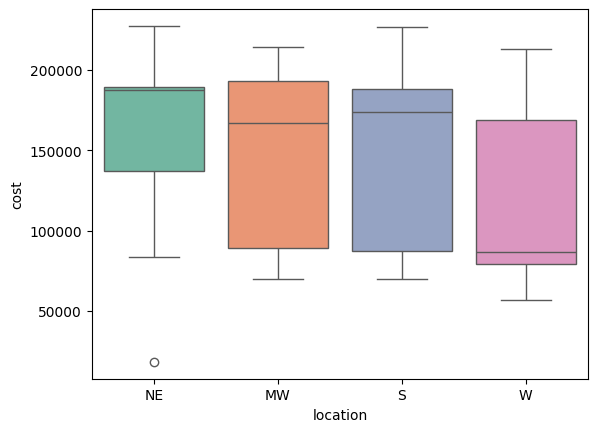

In [11]:
#Boxplot
sns.boxplot(data=df, x='location', y='cost', palette='Set2')
plt.show()

## Interpretación
`NE`: Se observa un valor atípico inferior. El 50% central de los costos se encuentra aproximadamente entre 140,000 y 190,000 dólares, con una mediana relativamente alta en comparación con otras regiones.

`MW`: No se observan valores atípicos. La dispersión es amplia y la mediana se encuentra aproximadamente en el centro del rango intercuartílico, lo que sugiere una distribución relativamente equilibrada.

`S`: Presenta una variabilidad similar a `MW`, aunque con una mediana ligeramente superior, indicando costos generalmente más altos.

`W`: Posee la mediana más baja entre las regiones analizadas. Aunque existe una dispersión considerable, la mayoría de los costos se concentran en valores inferiores respecto a las demás regiones.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [12]:
#Construcción del modelo
X = df_encoded[['cost', 'location_NE', 'location_S', 'location_W']]
y = df_encoded['salary']

model = LinearRegression()
model.fit(X, y)


LinearRegression()

In [13]:
#Coeficientes
print("Intercepto:", model.intercept_)
print("Coeficientes:", model.coef_)

Intercepto: 84988.71622754404
Coeficientes: [ 6.05175342e-02  1.20328197e+04  2.80034503e+03 -7.72142010e+03]


In [14]:
intercept = model.intercept_
coefficients = model.coef_
equation = f"Salary = {intercept} "
for i, coef in enumerate(coefficients):
  equation += f"+ ({coef} * {X.columns[i]}) "

equation #se obtiene el modelo con los coefic

'Salary = 84988.71622754404 + (0.06051753417141942 * cost) + (12032.819692403562 * location_NE) + (2800.345026332499 * location_S) + (-7721.420103045976 * location_W) '

## Interpretación
Se construyó un modelo de regresión lineal para predecir el salario de los egresados utilizando el costo de la universidad y la ubicación geográfica.

El intercepto es 84,988.72, lo que representa el salario estimado para una universidad de la región `MW` (categoría de referencia) cuando el costo es cero.
El coeficiente del costo es 0.0605, por lo que, manteniendo constante la ubicación, por cada dólar adicional de costo el salario esperado aumenta aproximadamente 0.06 dólares. Equivalentemente, un incremento de 10,000 dólares en el costo se asocia con un aumento aproximado de 605 dólares en el salario.


El coeficiente de `location_NE` es 12,032.82, indicando que las universidades ubicadas en el noreste presentan salarios esperados aproximadamente 12,033 dólares superiores a los de la región MW para un mismo costo.

El coeficiente de `location_S` es 2,800.35, por lo que las universidades del sur presentan salarios ligeramente superiores a los de `MW`, manteniendo constante el costo.

El coeficiente de `location_W` es -7,721.42, lo que indica que las universidades del oeste presentan salarios aproximadamente 7,721 dólares menores que las de `MW` para un mismo costo.


##Conclusión

La ubicación parece influir en el salario de los egresados. La región `NE` muestra el mayor efecto positivo sobre el salario, mientras que la región `W` presenta un efecto negativo respecto a la categoría de referencia (`MW`). Además, el costo de la universidad tiene una relación positiva con el salario esperado, aunque el efecto es relativamente moderado.

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

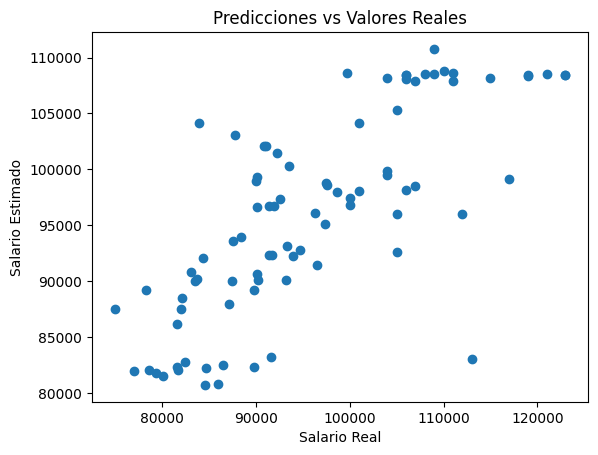

In [15]:
#Predicciones vs valores reales
y_pred = model.predict(X)
plt.scatter(y, y_pred)
plt.xlabel('Salario Real')
plt.ylabel('Salario Estimado')
plt.title('Predicciones vs Valores Reales')
plt.show()

Text(0, 0.5, 'Error Residual')

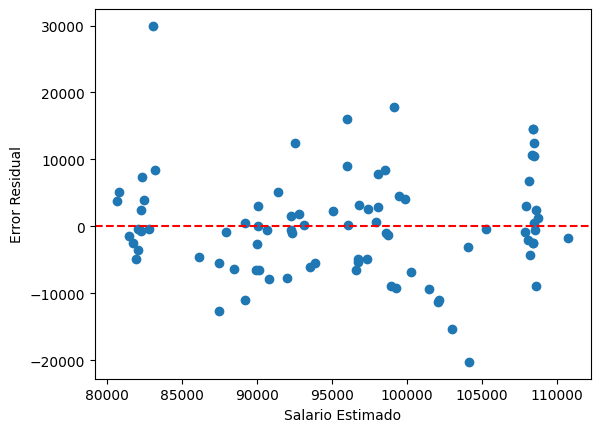

In [16]:
#Errores residuales
residuales = y - y_pred
plt.scatter(y_pred, residuales)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Salario Estimado')
plt.ylabel('Error Residual')

## Interpretación

El gráfico de predicciones vs. valores reales muestra una relación positiva entre ambas variables, lo que indica que el modelo logra captar la tendencia general entre el costo, la ubicación y el salario de los egresados. Sin embargo, la dispersión de los puntos alrededor de la tendencia esperada sugiere que aún existe una cantidad considerable de variabilidad que no está siendo explicada completamente por el modelo.

Por otro lado, el gráfico de residuos muestra que la mayoría de los errores se distribuyen alrededor de cero sin presentar patrones claramente definidos, lo que indica que el ajuste lineal es razonable. No obstante, se observan varios residuos relativamente grandes y algunos valores atípicos, especialmente para ciertas universidades donde la diferencia entre el salario real y el estimado es considerable. Esto sugiere que, aunque el modelo captura la tendencia general de los datos, todavía existen factores adicionales que podrían influir en el salario y que no están siendo considerados mediante las variables incluidas actualmente. En general, el modelo presenta un ajuste aceptable, pero las gráficas evidencian oportunidades de mejora en su capacidad predictiva.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [17]:
#MSE
mse = mean_squared_error(y, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 60480269.14657189


In [18]:
#R2 score
r2 = r2_score(y, y_pred)
print("R2 Score:", r2)

R2 Score: 0.5705089716684086


## Interpretación

Para evaluar el modelo se calcularon el MSE y el coeficiente de determinación R2R^2R2. Se obtuvo un MSE de 60,480,269.15, lo que indica que existen diferencias considerables entre algunos salarios reales y los estimados por el modelo. Esto coincide con lo observado en las gráficas de residuos, donde se identificaron varias observaciones con errores relativamente elevados.

Por otro lado, el valor de Rscore = 0.571 indica que el modelo explica aproximadamente el 57% de la variabilidad del salario, por lo que logra capturar una parte importante de la información contenida en los datos, aunque todavía queda un porcentaje considerable sin explicar.

Una posible razón de este resultado es que el modelo únicamente utiliza el costo y la ubicación de la universidad como variables predictoras. Sin embargo, el dataset también incluye información sobre si la universidad es pública o privada, una característica que podría influir tanto en el costo como en el salario de los egresados. Por esta razón, sería interesante incorporar esta variable en futuras versiones del modelo y analizar si contribuye a mejorar su capacidad explicativa y predictiva.

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [19]:
modelo_anova = ols('salary ~ cost + C(location)', data=df).fit()

anova_results = anova_lm(modelo_anova)

print(anova_results)

               df        sum_sq       mean_sq          F        PR(>F)
C(location)   3.0  6.040930e+09  2.013643e+09  31.335738  1.694998e-13
cost          1.0  7.878166e+08  7.878166e+08  12.259774  7.600629e-04
Residual     80.0  5.140823e+09  6.426029e+07        NaN           NaN


## Conclusión

A lo largo del análisis se observó que existe una relación positiva entre el costo de una universidad y el salario de sus egresados, aunque esta relación cambia dependiendo de la región. Las gráficas exploratorias mostraron diferencias entre ubicaciones y sugirieron que tanto el costo como la región pueden influir en el salario.

Posteriormente, se construyó un modelo de regresión lineal utilizando estas variables. Los resultados mostraron que el costo tiene un efecto positivo sobre el salario estimado y que algunas regiones presentan salarios mayores o menores respecto a otras. Sin embargo, las gráficas de predicciones y residuos evidenciaron que el modelo no logra explicar completamente el comportamiento de todos los datos, ya que existen observaciones con errores relativamente grandes.

La evaluación del modelo arrojó un R2R^2R2 de aproximadamente 0.57, por lo que el modelo explica cerca del 57% de la variabilidad del salario. Esto indica que el ajuste es razonable, aunque todavía existe una parte importante de la variabilidad que no está siendo capturada.

Finalmente, el análisis realizado confirma que el costo y la ubicación tienen una influencia significativa sobre el salario. No obstante, una posible mejora sería incorporar la variable que indica si la universidad es pública o privada, ya que podría aportar información adicional y ayudar a obtener predicciones más precisas.